# Lecture 4: Python Data Structures - Exercises

## Exercise 0: Feedback

Feedback helps me improve my teaching. Please consider leaving me some feedback on this form (it's anonymous!) about anything you liked or disliked about my teaching today:

https://forms.office.com/e/tTWAeqY28j Thank you!

# Part I - Basic types

## Exercise 1.1: Comprehensions & Generators

Run the following code block. Here we are creating a `list` (via a list comprehension), a `dict` (via a dict comprehension), and a `generator`.

In [1]:
my_list = [ _**2 for _ in range(5)]
my_dict = {_**2:_ for _ in range(5)}
my_generator = ( _**2 for _ in range(5))

Now run each of these blocks several times

In [2]:
for i in my_list:
    print(i)

0
1
4
9
16


In [3]:
for i in my_dict:
    print(i, my_dict[i])

0 0
1 1
4 2
9 3
16 4


In [4]:
for i in my_generator:
    print(i)

0
1
4
9
16


In [5]:
for i in my_generator:
    print(i)

What did you notice? Are there any differences in the behaviour between these three objects? Is the output what you expected to see?

Can you explain why the last one behaves differently after the second time you run it?

Try using the `type` command to see the class of each of `my_list` and `my_generator`. Is this what you expected?

In [6]:
print(type(my_list))
print(type(my_generator))

<class 'list'>
<class 'generator'>


Generators are useful to create long sequences without using up the memory to store all the values. In a short syntax they let you create iterators to use elsewhere

One good use of generators:

In [7]:
import numpy as np

val1 = np.array([_ for _ in range(1000)]) # creates a temporary list, then turns that into an array
val2 = np.fromiter((_ for _ in range(1000)), dtype=int) # just the array, no temporary memory required

## Exercise 1.2: Fun with lists

We can time a how long a function takes to run fairly accurately using the `timeit` module. One way to do this is to call the `timeit.repeat` function:

```python
import timeit
t = timeit.repeat('lst.pop(1)', setup='lst = [1, 2, 3, 4, 5]', repeat=100, number=1)
print(t)
```

Here `repeat` is the number of runs to do, `number` is the number of copies within each run. Since we are only interested in the timing of the list operation, not the creation of the list, we use the `setup` argument to create the list: this then happens before the timing starts. 

For operations like this on a list, we need to set `number=1`, otherwise our list will keep growing or shrinking with each iteration of the timeit timer (if you are interested in this, you can test it by setting `number` to some value larger than the length of the list and using the pop command - at some point the list will be empty, and can no longer pop a value). The solution here is to use `repeat`, so for each iteration, the setup code will be run, before the timer starts, then the append operation is timed, before we start all over again.

This will return a list with a time for each iteration. In this example, there will be 100 times in that list. You can inspect these yourself, the most interesting values will be the mean and minimum in the list. The minimum is interesting as that will be a good indication of how quickly things _can_ run on your computer. If there is lots of variation in those times, you may need to increase `repeat` to a larger number to get some meaningful results.

### Try these timing operations yourself

Using the method above (or your own preferred alternative) try timing the following operations:

- Append one value to a list of 5 elements
- Insert a new value to the 3rd place( i.e. index 2) in a list of 5 elements
- Remove the 3rd value in a list of 6 elements
- Remove the 3rd value in a list of 600 elements.

In [8]:
import timeit

# Append a value
t = timeit.repeat('lst.append(6)', setup='lst = [1, 2, 3, 4, 5]', repeat=100, number=1)
print(f"Average time for appending to a 5-item list: {np.mean(t):8.4e}")
print(f"Minimum time for appending to a 5-item list: {np.min(t):8.4e}")

Average time for appending to a 5-item list: 1.1380e-07
Minimum time for appending to a 5-item list: 4.0978e-08


In [9]:
# Insert a value
t = timeit.repeat('lst.insert(2, 6)', setup='lst = [1, 2, 3, 4, 5]', repeat=100, number=1)
print(f"Average time for inserting in a 5-item list: {np.mean(t):8.4e}")
print(f"Minimum time for inserting in a 5-item list: {np.min(t):8.4e}")

Average time for inserting in a 5-item list: 1.8293e-07
Minimum time for inserting in a 5-item list: 8.3004e-08


Note that this is a little slower than the append operation

In [10]:
# Remove a value
t = timeit.repeat('lst.pop(2)', setup='lst = [1, 2, 3, 4, 5]', repeat=100, number=1)
print(f"Average time for removing an item from a 5-item list: {np.mean(t):8.4e}")
print(f"Minimum time for removing an item from a 5-item list: {np.min(t):8.4e}")

Average time for removing an item from a 5-item list: 1.8038e-07
Minimum time for removing an item from a 5-item list: 8.3004e-08


Again, this is slower than the append operation, but about the same as the insert operation

In [11]:
# Remove a value in a large list
t = timeit.repeat('lst.pop(2)', setup='lst = list(range(600))', repeat=100, number=1)
print(f"Average time for removing an item from a 600-item list: {np.mean(t):8.4e}")
print(f"Minimum time for removing an item from a 600-item list: {np.min(t):8.4e}")

Average time for removing an item from a 600-item list: 2.6956e-07
Minimum time for removing an item from a 600-item list: 2.0798e-07


Quite a lot slower than on the smaller list

## Exercise 1.3: Time filling different length lists and plot the results
Now, using the function `fill_list` below, time how long it takes to append an element to a list for various sizes. Do you think you can spot the times when the list has to expand itself?

In [12]:
def fill_list(n):
    "Fill a list with n values"
    return list(range(n))

# Let's time this for lists of sizes from 0 to 500
ns = range(500)

# Create empty lists to store our average and minimum times
avgtimes = []
mintimes = []

# for each length of list we want to time
for i in ns:
      
    # We will import the fill_list function, and the integer i, so timeit can use those in the setup
    # Let's test this length of list 1000 times
    t = timeit.repeat('lst.append(500)',
                  setup="from __main__ import fill_list, i; lst = fill_list(i)",
                  repeat=1000, number=1)
    
    avgtimes.append(np.mean(t))
    mintimes.append(np.min(t))

Try plotting the run times. It's likely things won't be too obvious. 

Since we haven't covered plotting with `matplotlib` in the lectures yet (come back for lecture 7), here's a simple way to plot two arrays/lists against each other, assuming you have a list or array of lengths (`ns`) and a list or array of times (`times`):

Text(0, 0.5, 'Average time')

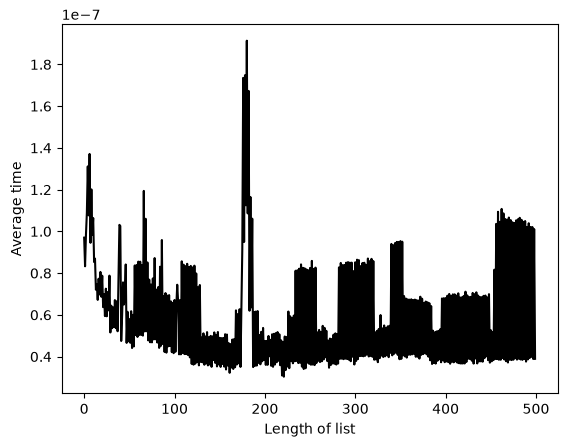

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.plot(ns, avgtimes, 'k-')
ax.set_xlabel("Length of list")
ax.set_ylabel("Average time")


Text(0, 0.5, 'Minimum time')

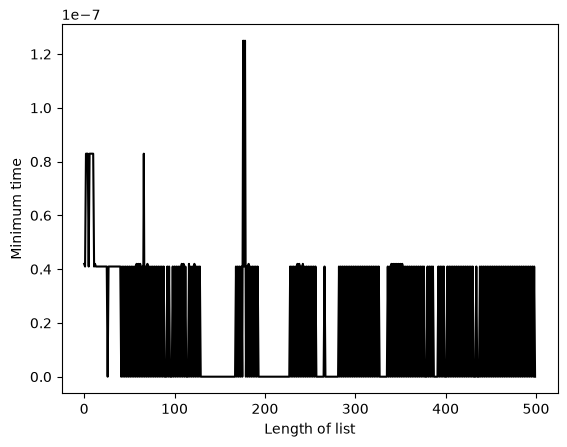

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.plot(ns, mintimes, 'k-')
ax.set_xlabel("Length of list")
ax.set_ylabel("Minimum time")


## Exercise 1.4: Hashes and dicts:

Python exposes its basic hash operator as `hash()`. Try applying it to the following
- An integer (e.g. 3)
- A float (e.g. 3.0)
- A string (e.g. 'Hello World')

Can you observe any difference if you use elements with the same hash as keys in a dictionary?

In [15]:
# write your code here

print(f"hash of integer 3: {hash(3)}")
print(f"hash of float 3.0: {hash(3.0)}")
print(f"hash of string 'Hello World': {hash('Hello World')}")

mydict = {3: "int 3", 5: "int 5", 3.0: "float 3.0"}
print(f"mydict: {mydict}") # note the first item has been overwritten, because the last key has the same hash

hash of integer 3: 3
hash of float 3.0: 3
hash of string 'Hello World': -3200865207618809445
mydict: {3: 'float 3.0', 5: 'int 5'}


# Part II: Extended types

## The `collections` module

The `collections` module contains a number of helpful data structures, including the `namedtuple` and `deque`.

### Exercise 2.1: `namedtuple`s

A `namedtuple` lets you quickly create a simple class for storing data without methods, much like a regular tuple but with named fields. 

In [16]:
from collections import namedtuple

Point = namedtuple('Point', ('x', 'y', 'z'))

point1  = Point(1,2,3)
print(point1.z)
point2  = Point(z=1, x=2, y=3)
print(point2.z)


3
1


Try to create a `namedtuple`  for a class called `Person`, with attributes `name` and `age`.

In [17]:
## Write your code here
# Define a new namedtuple type called 'Person' with attributes 'name' and 'age'
Person = namedtuple('Person', ['name', 'age'])

# Create a new instance of Person
arthur = Person(name="Arthur", age=42)

# Access the fields
print(arthur.name)  # Outputs: Arthur
print(arthur.age)   # Outputs: 42


Arthur
42


### Exercise 2.2: `deque`s

`deque`s are short for "double ended queues" and act like a list to which values can be added on either end.

In [18]:
from collections import deque

a = deque((1,2,3))

a.append(4)
a.appendleft(0)
print(a)

a.pop()
a.popleft()
print(a)

deque([0, 1, 2, 3, 4])
deque([1, 2, 3])


Time how long it takes to add or pop a value on the right (`append()` or `pop()`) and on the left (`appendleft()` or `popleft()`). How does this compare to using a regular Python list.

In [19]:
## Write your code here

# Append to the right of a deque
dar = timeit.repeat('dq.append(6)', setup='from __main__ import deque; dq = deque(range(1000))',
                    repeat=100, number=1)
# Append to the left of a deque
dal = timeit.repeat('dq.appendleft(6)', setup='from __main__ import deque; dq = deque(range(1000))',
                    repeat=100, number=1)
# Pop from the right of a deque
dpr = timeit.repeat('dq.pop()', setup='from __main__ import deque; dq = deque(range(1000))',
                    repeat=100, number=1)
# Pop the left of a deque
dpl = timeit.repeat('dq.popleft()', setup='from __main__ import deque; dq = deque(range(1000))',
                    repeat=100, number=1)

# Append to the right of a list
lar = timeit.repeat('lst.append(6)', setup='lst = list(range(1000))',
                    repeat=100, number=1)
# Append to the left of a list
lal = timeit.repeat('lst.insert(0, 6)', setup='lst = list(range(1000))',
                    repeat=100, number=1)
# Pop from the right of a list
lpr = timeit.repeat('lst.pop()', setup='lst = list(range(1000))',
                    repeat=100, number=1)
# Pop the left of a list
lpl = timeit.repeat('lst.pop(0)', setup='lst = list(range(1000))',
                    repeat=100, number=1)

print(f"Average time to append to the right of a deque ({np.mean(dar):8.4e}) vs a list ({np.mean(lar):8.4e})")
print(f"Average time to append to the left of a deque  ({np.mean(dal):8.4e}) vs a list ({np.mean(lal):8.4e})")
print()

print(f"Average time to pop from the right of a deque  ({np.mean(dpr):8.4e}) vs a list ({np.mean(lpr):8.4e})")
print(f"Average time to pop from the left of a deque   ({np.mean(dpl):8.4e}) vs a list ({np.mean(lpl):8.4e})")
print()
print(f"Minimum time to append to the right of a deque ({np.min(dar):8.4e}) vs a list ({np.min(lar):8.4e})")
print(f"Minimum time to append to the left of a deque  ({np.min(dal):8.4e}) vs a list ({np.min(lal):8.4e})")
print()

print(f"Minimum time to pop from the right of a deque  ({np.min(dpr):8.4e}) vs a list ({np.min(lpr):8.4e})")
print(f"Minimum time to pop from the left of a deque   ({np.min(dpl):8.4e}) vs a list ({np.min(lpl):8.4e})")

Average time to append to the right of a deque (1.5749e-07) vs a list (2.6535e-07)
Average time to append to the left of a deque  (1.2038e-07) vs a list (3.9378e-07)

Average time to pop from the right of a deque  (1.3715e-07) vs a list (9.5523e-08)
Average time to pop from the left of a deque   (1.1919e-07) vs a list (2.4496e-07)

Minimum time to append to the right of a deque (8.2946e-08) vs a list (1.2497e-07)
Minimum time to append to the left of a deque  (8.2946e-08) vs a list (2.9104e-07)

Minimum time to pop from the right of a deque  (8.2946e-08) vs a list (4.1968e-08)
Minimum time to pop from the left of a deque   (4.2026e-08) vs a list (2.0798e-07)


Notice that the operations on the left of the list are much slower than on a deque, and much slower than operations on the right of the list

# Part III - Python Classes


## Exercise 3: Operator Overloading

Try to write your own class to implement a [complex number](https://wikipedia.com/Complex_numbers) (note that Python already implements complex numbers as `complex(1,2)` or 1+2j, so this isn't something you would need to do  in live code).

You will need to store two `float` values, one to store the real part of the number, and one to store the imaginary part, and write the `__init__` routine to store them. If you call them `real` and `imag` then your new class will be more interoperable with the builtin one.

The rules for arithmatic for two complex numbers, $z_1 = x_1 + i y_1$ and $z_2 = x_2+iy_2$ are:
$$z_1+z_2 = x_1+x_2 +i \left(y_1+y_2\right)$$
$$z_1-z_2 = x_1-x_2 +i \left(y_1-y_2\right)$$
$$z_1\times z_2 = x_1\times x_2-y_1\times y_2 +i \left(x_1\times y_2+x_2\times y_1\right)$$
$$\frac{z_1}{z_2} = \frac{x_1\times x_2+y_1\times y_2 +i \left(x_2\times y_1-x_1\times y_2\right)}{x_2^2+y_2^2}$$

can you implement these via overloading? What happens if you try to add a normal (i.e. real) float as $z_1+x_2$ or $x_2 + z_1$? If you have time, can you fix this?

In [20]:
class MyComplex:
    
    def __init__(self, real, imag):
        '''
        store the real and imaginary parts
        '''
        self.real = real
        self.imag = imag

    def __str__(self):
        '''
        function to print out the values nicely
        '''
        if self.imag >= 0:
            sym = "+"
        else:
            sym = ""  # Don't need a + symbol here if the imaginary part is negative
        return f"{self.real:g}{sym}{self.imag:g}j"

    def __add__(self, other):
        '''
        add two complex numbers together
        '''
        newreal = self.real + other.real
        newimag = self.imag + other.imag
        return MyComplex(newreal, newimag)
    
    def __sub__(self, other):
        '''
        subtract a complex number from this one
        '''
        newreal = self.real - other.real
        newimag = self.imag - other.imag
        return MyComplex(newreal, newimag)

    def __mul__(self, other):
        '''
        multiply two complex numbers together
        '''
        newreal = self.real * other.real - self.imag * other.imag
        newimag = self.real * other.imag + other.real * self.imag
        return MyComplex(newreal, newimag)

    def __truediv__(self, other):
        '''
        divide this complex number by another complex number
        '''
        denom = (other.real**2 + other.imag**2)
        newreal = (self.real * other.real + self.imag * other.imag) / denom
        newimag = (other.real * self.imag - self.real * other.imag) / denom
        return MyComplex(newreal, newimag)

# First let's create two complex numbers from our class
cpx1 = MyComplex(2, 5)
cpx2 = MyComplex(3, 7)

# And let's print those to check the __str__ method works
print(cpx1)
print(cpx2)

# Now let's try some arithmetic
print(f"Add      : {cpx1 + cpx2}")
print(f"Subtract : {cpx1 - cpx2}")
print(f"Multiply : {cpx1 * cpx2}")
print(f"Divide   : {cpx1 / cpx2}")

2+5j
3+7j
Add      : 5+12j
Subtract : -1-2j
Multiply : -29+29j
Divide   : 0.706897+0.0172414j


In [21]:
# Let's check we got it correct with some native python complex numbers
c1 = complex(2, 5)
c2 = complex(3, 7)

print(f"Add      : {c1 + c2:g}")
print(f"Subtract : {c1 - c2:g}")
print(f"Multiply : {c1 * c2:g}")
print(f"Divide   : {c1 / c2:g}")

Add      : 5+12j
Subtract : -1-2j
Multiply : -29+29j
Divide   : 0.706897+0.0172414j
